# Paint

You will build: a sunset seen through a round window, painted with gradients, a wave pattern, a fading mask
and a clip.

Run it from this folder with ``python paint.py``, or open ``paint.ipynb``.

In [1]:
import svgwriter as svg

A gradient is a fill: the sky blends from yellow through pink to purple.

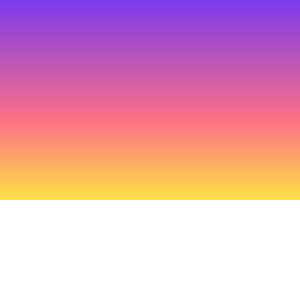

In [2]:
SIZE = 300
doc = svg.Document(SIZE, SIZE)
view = doc.group()
sky = svg.LinearGradient(svg.Stop(0, "#7c3aed"), svg.Stop(0.6, "#fb7185"), svg.Stop(1, "#fde047"),
                         x1=0, y1=0, x2=0, y2=1)
view.add(svg.rect(0, 0, SIZE, 200, fill=sky))
doc

A radial gradient spreads out from a centre: a glowing sun.

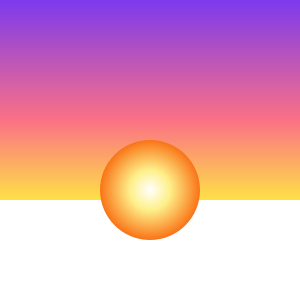

In [3]:
sun = svg.RadialGradient(svg.Stop(0, "white"), svg.Stop(0.4, "#fef08a"), svg.Stop(1, "#f97316"))
view.add(svg.circle(SIZE / 2, 190, 50, fill=sun))
doc

A `Pattern` repeats a small tile: little wave lines fill the sea.

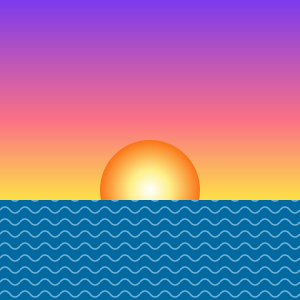

In [4]:
wave = svg.path("M0 6 Q5 0 10 6 T20 6", fill="none", stroke="#bae6fd", stroke_width=1.5)
waves = doc.define(svg.Pattern(wave, width=20, height=12, pattern_units="userSpaceOnUse"))
view.add(svg.rect(0, 200, SIZE, 100, fill="#0369a1"))
view.add(svg.rect(0, 200, SIZE, 100, fill=waves, opacity=0.6))
doc

A `Mask` fades a shape: white keeps it, black hides it. The sun's reflection fades out toward the bottom.

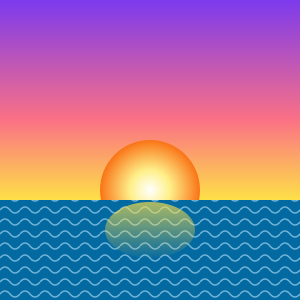

In [5]:
fade = svg.LinearGradient.vertical("white", "black")
veil = doc.define(svg.Mask(svg.rect(100, 200, 100, 60, fill=fade)))
view.add(svg.ellipse(SIZE / 2, 230, 45, 28, fill="#fde047", opacity=0.7, mask=veil))
doc

A `ClipPath` keeps only what lies inside it: the whole view becomes a round window.

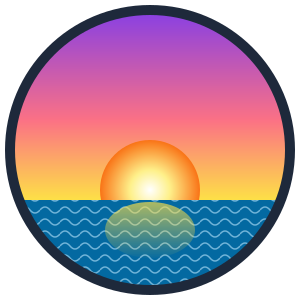

In [6]:
window = doc.define(svg.ClipPath(svg.circle(SIZE / 2, SIZE / 2, 140)))
view.clip_path = window
doc.circle(SIZE / 2, SIZE / 2, 140, fill="none", stroke="#1e293b", stroke_width=10)
doc

Save it. Next: [09 Filters](../09_filters/filters.py) adds shadows and glows.

In [7]:
doc.save("08_paint.svg")